## Importando as bibliotecas do python

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

## Carregamento e Inspeção 

In [22]:
df = pd.read_csv('ecommerce_preparados.csv')
df.describe()

,Unnamed: 0,Nota,N_Avaliações,Desconto,Preço,Nota_MinMax,N_Avaliações_MinMax,Desconto_MinMax,Preço_MinMax,Marca_Cod,Material_Cod,Temporada_Cod,Qtd_Vendidos_Cod,Marca_Freq,Material_Freq
count,2199.000000,1559.000000,1559.000000,874.000000,1964.000000,1559.000000,1559.000000,874.000000,1964.000000,2199.000000,2199.000000,2199.000000,1973.000000,2199.000000,1332.000000
mean,1102.356526,4.560936,204.062219,15.457666,102.705713,0.837384,0.022374,0.171437,0.156587,440.440655,118.055935,3.418372,728.044602,0.006109,0.080198
std,637.791961,0.362854,578.455265,10.929166,69.976425,0.134390,0.063735,0.179167,0.119328,237.064233,60.987133,2.714090,3621.819900,0.009910,0.073812
min,0.000000,2.300000,1.000000,5.000000,10.880000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000455,0.000455
25%,549.500000,4.400000,8.000000,8.000000,50.192500,0.777778,0.000771,0.049180,0.067038,239.500000,62.500000,1.000000,5.000000,0.000910,0.005457
50%,1103.000000,4.600000,27.000000,11.000000,78.970000,0.851852,0.002865,0.098361,0.116111,463.000000,122.000000,3.000000,50.000000,0.001819,0.030014
75%,1654.500000,4.800000,119.500000,20.000000,139.152500,0.925926,0.013056,0.245902,0.218738,642.500000,178.000000,7.000000,100.000000,0.007731,0.176444
max,2206.000000,5.000000,9077.000000,66.000000,597.300000,1.000000,1.000000,1.000000,1.000000,841.000000,178.000000,9.000000,50000.000000,0.042292,0.176444


## Verificar se o dados estão sanitizados

### Tratando nulos

In [23]:
df.isnull().sum()

Unnamed: 0                0
Título                    0
Nota                    640
N_Avaliações            640
Desconto               1325
Marca                     0
Material                867
Gênero                   79
Temporada                 0
Review1                 684
Review2                 845
Review3                 966
Qtd_Vendidos              0
Preço                   235
Nota_MinMax             640
N_Avaliações_MinMax     640
Desconto_MinMax        1325
Preço_MinMax            235
Marca_Cod                 0
Material_Cod              0
Temporada_Cod             0
Qtd_Vendidos_Cod        226
Marca_Freq                0
Material_Freq           867
dtype: int64

In [24]:
dftratado = df.copy()

### Tratar descontos com valores nulos


In [25]:
dftratado['Desconto'] = dftratado['Desconto'].fillna(0)

### Tratar Gênero não informado

In [26]:
dftratado['Gênero'] = dftratado['Gênero'].fillna('Não Informado')

### Tratar Material não informado

In [27]:
dftratado['Material'] = dftratado['Material'].fillna('Não Informado')



In [28]:
dftratado['Desconto_MinMax'] = dftratado['Desconto_MinMax'].fillna(0)

## Verificar se há registros duplicados

In [29]:
dftratado.duplicated().sum()

np.int64(0)

In [30]:
# 1. Ver se há duplicadas ignorando a coluna de índice 'Unnamed: 0'
cols_sem_indice = [col for col in dftratado.columns if col != 'Unnamed: 0']
print("Duplicadas reais de produto:", dftratado.duplicated(subset=cols_sem_indice).sum())

Duplicadas reais de produto: 214


In [ ]:

if 'Unnamed: 0' in dftratado.columns:
    dftratado = dftratado.drop(columns=['Unnamed: 0'])


dftratado = dftratado.drop_duplicates().reset_index(drop=True)


print("Duplicadas restantes após limpeza:", dftratado.duplicated().sum())
print("Total de linhas únicas para análise:", dftratado.shape[0])

Duplicadas restantes após limpeza: 0
Total de linhas únicas para análise: 1985


## Gráficos


### Histogrma para preços

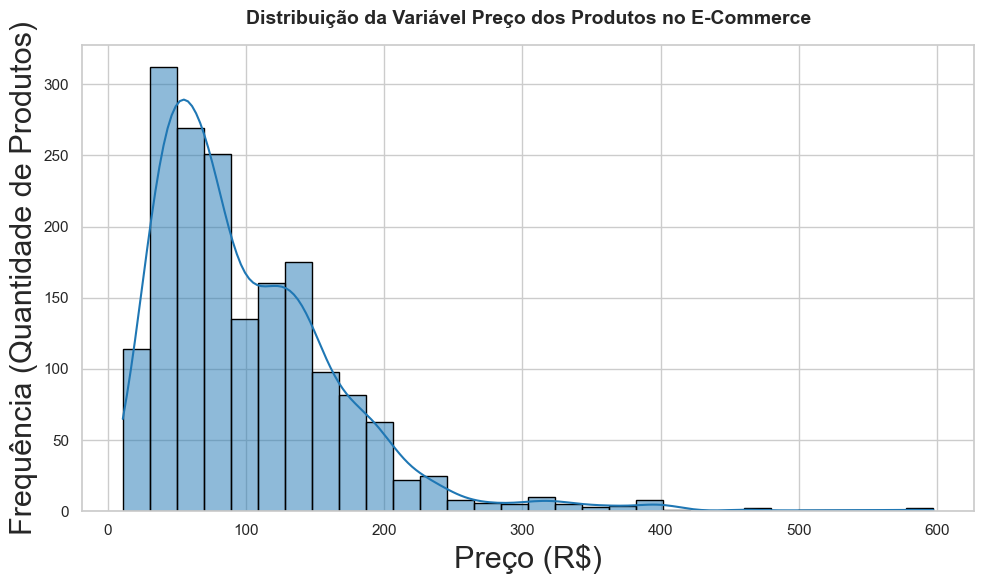

In [36]:
sb.set_theme(style='whitegrid')
plt.figure(figsize=(10,6))

sb.histplot(
    data=dftratado.dropna(subset=['Preço']),
    x='Preço',
    kde=True,
    bins=30,
    color='#1f77b4',
    edgecolor='black'
)

plt.title('Distribuição da Variável Preço dos Produtos no E-Commerce', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Preço (R$)', fontsize=22)
plt.ylabel('Frequência (Quantidade de Produtos)', fontsize=22)

plt.tight_layout()
plt.show()



#### Observação: Há uma grande quantidade de produtos entre R$ 35 a R$ 50 no catálogo. Mais de 300

### Gráfico de Dispersão entre Preço e Número de Avaliações

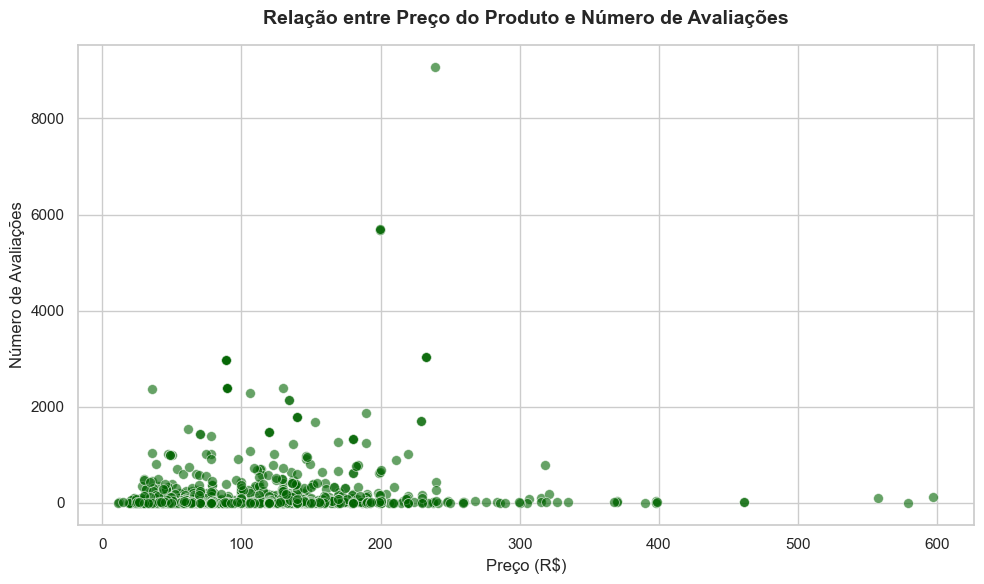

In [37]:
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))


sb.scatterplot(
    data=dftratado.dropna(subset=['Preço', 'N_Avaliações']),
    x='Preço',
    y='N_Avaliações',
    alpha=0.6,          
    color='darkgreen',  
    s=50                
)


plt.title('Relação entre Preço do Produto e Número de Avaliações', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Preço (R$)', fontsize=12)
plt.ylabel('Número de Avaliações', fontsize=12)


plt.tight_layout()
plt.show()

#### Observação: A maior parte de avaliações de produtos se concentra em produtos de baixo valor. Abaixo de R$ 200, mostrando que produtos de valores maiores são pouco avaliados

### Mapa de Calor entre Qtd. Vendidas, Preço, Desconto, Número de Avaliações, Nota

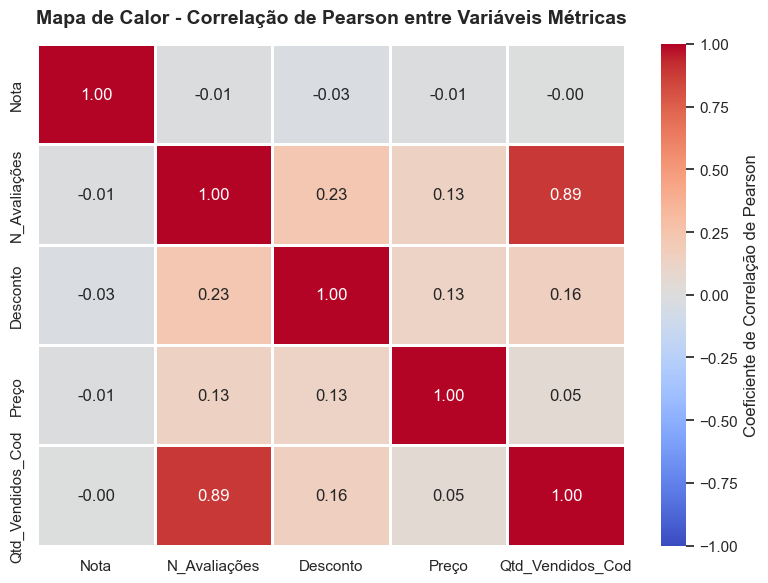

In [ ]:

cols_metricas = ['Nota', 'N_Avaliações', 'Desconto', 'Preço', 'Qtd_Vendidos_Cod']
matriz_corr = dftratado[cols_metricas].corr()


plt.figure(figsize=(8, 6))


sb.heatmap(
    matriz_corr, 
    annot=True,            
    cmap='coolwarm',       
    fmt=".2f",             
    vmin=-1, 
    vmax=1, 
    linewidths=0.8,
    cbar_kws={'label': 'Coeficiente de Correlação de Pearson'}
)


plt.title('Mapa de Calor - Correlação de Pearson entre Variáveis Métricas', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

#### Observação: Quanto mais um produto é vendido, mais avaliações ele possui

### Gráfico de Barras Matériais dos Produtos Disponíveis


C:\Users\André\AppData\Local\Temp\ipykernel_28424\986956125.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sb.barplot(


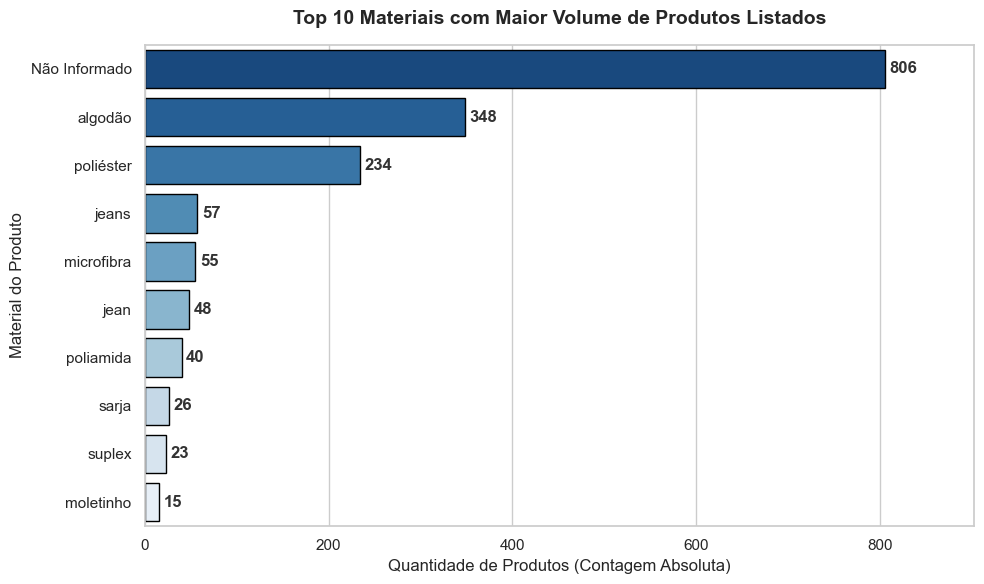

In [ ]:

top_materiais = dftratado['Material'].value_counts().head(10)


sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))


ax = sb.barplot(
    x=top_materiais.values, 
    y=top_materiais.index, 
    palette='Blues_r',
    edgecolor='black'
)


for i, v in enumerate(top_materiais.values):
    plt.text(v + 5, i, str(v), va='center', fontweight='bold', color='#333333')


plt.title('Top 10 Materiais com Maior Volume de Produtos Listados', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de Produtos (Contagem Absoluta)', fontsize=12)
plt.ylabel('Material do Produto', fontsize=12)


plt.xlim(0, top_materiais.values.max() * 1.12)


plt.tight_layout()
plt.show()

#### OBS: Se destaca que a quantidade de Produtos com material não informado é a de maior prevalência

### Gráfico de Pizza de Produtos por Gênero

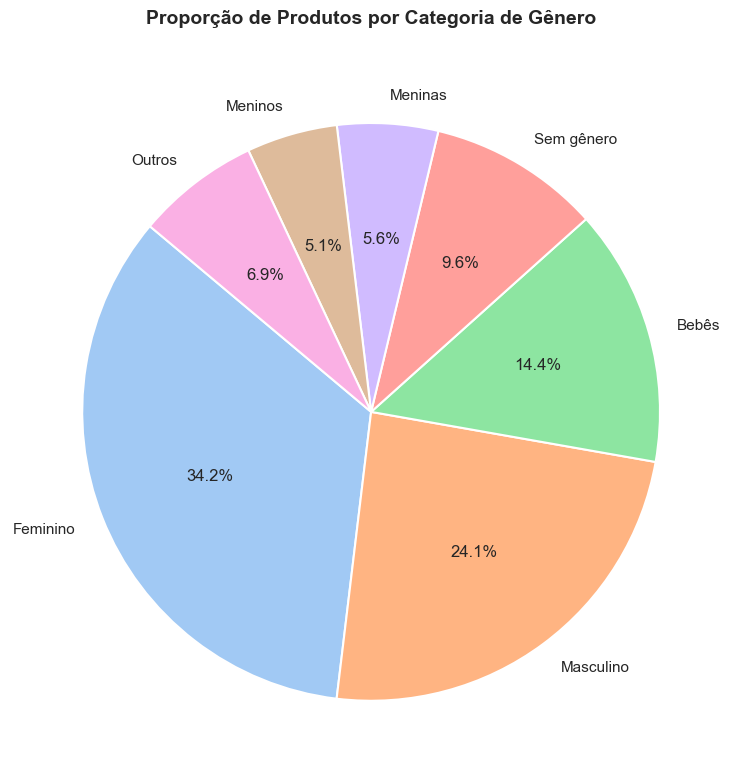

In [ ]:
dftratado['Gênero'] = dftratado['Gênero'].fillna('Não Informado')


genero_counts_raw = dftratado['Gênero'].value_counts()


top_categories = genero_counts_raw.head(6)
outros_sum = genero_counts_raw.iloc[6:].sum()

if outros_sum > 0:
    genero_clean = pd.concat([top_categories, pd.Series({'Outros': outros_sum})])
else:
    genero_clean = top_categories


plt.figure(figsize=(8, 8))

plt.pie(
    genero_clean.values, 
    labels=genero_clean.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sb.color_palette('pastel')[0:len(genero_clean)],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)


plt.title('Proporção de Produtos por Categoria de Gênero', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

#### OBS: Predominância de Produtos do Gênero Femino no Catálogo

### Gráfico de Densidade das Notas dos Produtos

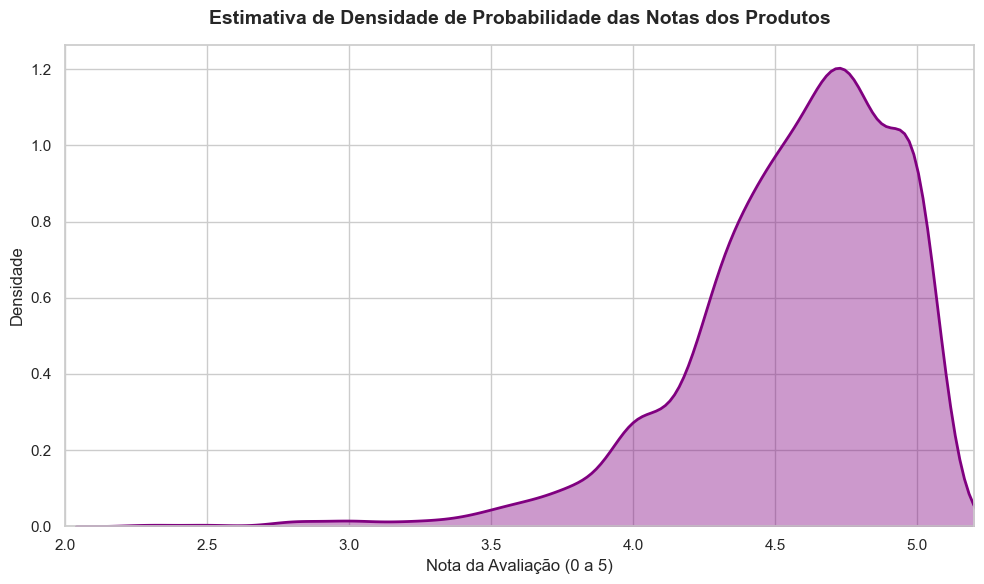

In [ ]:

sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

 
sb.kdeplot(
    data=dftratado.dropna(subset=['Nota']), 
    x='Nota',
    fill=True,       
    color='purple',  
    alpha=0.4,       
    linewidth=2      
)


plt.title('Estimativa de Densidade de Probabilidade das Notas dos Produtos', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Nota da Avaliação (0 a 5)', fontsize=12)
plt.ylabel('Densidade', fontsize=12)


plt.xlim(2.0, 5.2)

plt.tight_layout()
plt.show()

#### OBS: Assimetria negativa: Indica que a maioria das avaliões dos produtos está entre 4,2 e 4,8 estrelas

### Gráfico de Regressão Linear - Número de Avaliações e Vendas

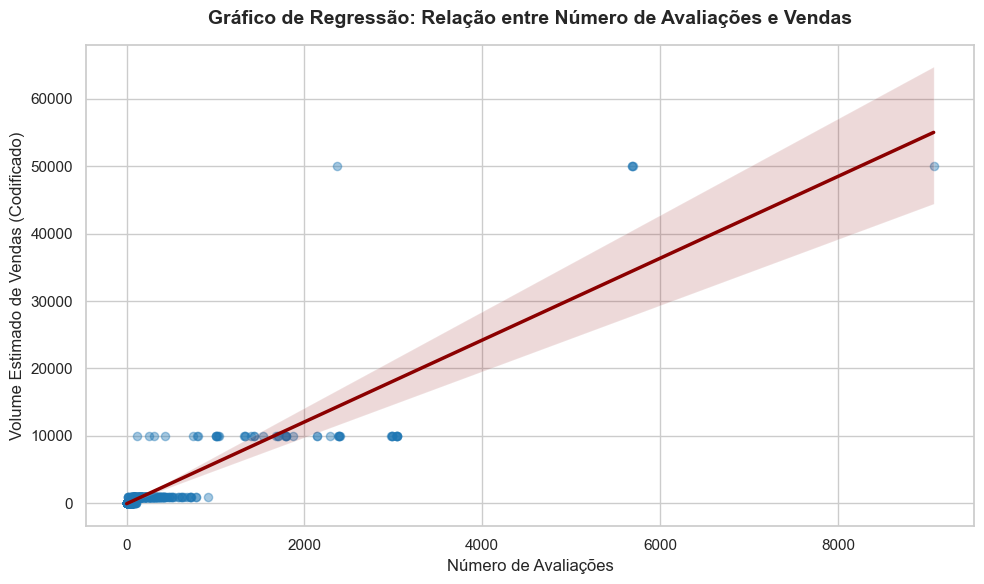

In [43]:

sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))


sb.regplot(
    data=dftratado.dropna(subset=['N_Avaliações', 'Qtd_Vendidos_Cod']),
    x='N_Avaliações',
    y='Qtd_Vendidos_Cod',
    scatter_kws={'alpha': 0.4, 'color': '#1f77b4', 's': 35}, 
    line_kws={'color': 'darkred', 'linewidth': 2.5}         
)


plt.title('Gráfico de Regressão: Relação entre Número de Avaliações e Vendas', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Avaliações', fontsize=12)
plt.ylabel('Volume Estimado de Vendas (Codificado)', fontsize=12)


plt.tight_layout()
plt.show()

#### OBS: Forte engajamento entre o pós-vendas e a quantidade de produtos vendidos